In [ ]:

import pandas as pd
import numpy as np

np.random.seed(42)
n = 100

# 1. Orders
orders = pd.DataFrame({
    "order_id": range(1001, 1001+n),
    "product_id": np.random.randint(1, 11, n),
    "customer_id": np.random.randint(101, 131, n),
    "quantity": np.random.randint(1, 5, n),
    "price": np.random.randint(200, 3000, n),
    "discount": np.random.choice([0, 5, 10, 20, 30], n)
})

# 2. Products
products = pd.DataFrame({
    "product_id": range(1, 11),
    "category": ["Fashion", "Electronics", "Home",
                 "Beauty", "Fashion"] * 2,
    "brand": [f"Brand{i}" for i in range(1, 11)],
    "size": np.random.choice(["S", "M", "L", "XL"], 10),
    "seller": np.random.choice(["Seller A", "Seller B",
                                "Seller C"], 10)
})

# 3. Customers
customers = pd.DataFrame({
    "customer_id": range(101, 131),
    "region": np.random.choice(
        ["North", "South", "East", "West"], 30),
    "order_history": np.random.randint(1, 20, 30)
})

# 4. Delivery
delivery = pd.DataFrame({
    "order_id": range(1001, 1001+n),
    "promised_days": np.random.randint(2, 7, n),
    "delivered_days": np.random.randint(1, 10, n),
    "courier": np.random.choice(["Courier A", "Courier B"], n)
})

# 5. Returns
returns = pd.DataFrame({
    "order_id": range(1001, 1001+n),
    "returned": np.random.choice([0, 1], n, p=[0.7, 0.3]),
    "reason": np.random.choice(
        ["Wrong Size", "Damaged", "Late Delivery",
         "Not as Expected", None], n)
})

# Save all five practice datasets
datasets = {
    "orders.csv": orders,
    "products.csv": products,
    "customers.csv": customers,
    "delivery.csv": delivery,
    "returns.csv": returns
}

for filename, df in datasets.items():
    df.to_csv(filename, index=False)

print("5 practice CSV files created successfully!")


5 practice CSV files created successfully!


In [ ]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load all datasets
orders = pd.read_csv("orders.csv")
products = pd.read_csv("products.csv")
customers = pd.read_csv("customers.csv")
delivery = pd.read_csv("delivery.csv")
returns = pd.read_csv("returns.csv")

# Display dataset shapes
print("Orders:", orders.shape)
print("Products:", products.shape)
print("Customers:", customers.shape)
print("Delivery:", delivery.shape)
print("Returns:", returns.shape)

# Display sample records
display(orders.head())
display(products.head())
display(customers.head())
display(delivery.head())
display(returns.head())


Orders: (100, 6)
Products: (10, 5)
Customers: (30, 3)
Delivery: (100, 4)
Returns: (100, 3)


,order_id,product_id,customer_id,quantity,price,discount
0,1001,7,112,3,462,10
1,1002,4,102,2,1987,5
2,1003,8,101,4,2391,5
3,1004,5,116,4,2593,10
4,1005,7,123,4,823,5


,product_id,category,brand,size,seller
0,1,Fashion,Brand1,L,Seller B
1,2,Electronics,Brand2,M,Seller C
2,3,Home,Brand3,M,Seller B
3,4,Beauty,Brand4,M,Seller A
4,5,Fashion,Brand5,S,Seller A


,customer_id,region,order_history
0,101,West,17
1,102,West,8
2,103,West,10
3,104,South,2
4,105,East,19


,order_id,promised_days,delivered_days,courier
0,1001,2,5,Courier A
1,1002,2,6,Courier B
2,1003,5,5,Courier B
3,1004,2,5,Courier A
4,1005,6,4,Courier A


,order_id,returned,reason
0,1001,0,NaN
1,1002,0,Wrong Size
2,1003,1,Wrong Size
3,1004,0,Wrong Size
4,1005,0,Late Delivery


In [ ]:

# Step 2: Data Quality Check

datasets = {
    "Orders": orders,
    "Products": products,
    "Customers": customers,
    "Delivery": delivery,
    "Returns": returns
}

for name, df in datasets.items():
    print("\n==========", name, "==========")
    print("Shape:", df.shape)
    print("\nMissing values:")
    print(df.isnull().sum())
    print("\nDuplicate rows:", df.duplicated().sum())
    print("\nData types:")
    print(df.dtypes)



========== Orders ==========
Shape: (100, 6)

Missing values:
order_id       0
product_id     0
customer_id    0
quantity       0
price          0
discount       0
dtype: int64

Duplicate rows: 0

Data types:
order_id       int64
product_id     int64
customer_id    int64
quantity       int64
price          int64
discount       int64
dtype: object

========== Products ==========
Shape: (10, 5)

Missing values:
product_id    0
category      0
brand         0
size          0
seller        0
dtype: int64

Duplicate rows: 0

Data types:
product_id     int64
category      object
brand         object
size          object
seller        object
dtype: object

========== Customers ==========
Shape: (30, 3)

Missing values:
customer_id      0
region           0
order_history    0
dtype: int64

Duplicate rows: 0

Data types:
customer_id       int64
region           object
order_history     int64
dtype: object

========== Delivery ==========
Shape: (100, 4)

Missing values:
order_id          0
prom

In [ ]:

# Step 3: Data Cleaning

# Remove duplicate records
orders = orders.drop_duplicates()
products = products.drop_duplicates()
customers = customers.drop_duplicates()
delivery = delivery.drop_duplicates()
returns = returns.drop_duplicates()

# Standardize text columns
products["category"] = products["category"].astype(str).str.strip().str.title()
products["brand"] = products["brand"].astype(str).str.strip()
products["size"] = products["size"].astype(str).str.strip().str.upper()
products["seller"] = products["seller"].astype(str).str.strip()

customers["region"] = customers["region"].astype(str).str.strip().str.title()
delivery["courier"] = delivery["courier"].astype(str).str.strip()

# Handle missing return reasons
returns["reason"] = returns["reason"].fillna("Unknown")

print("Data cleaning completed!")
print("Orders:", orders.shape)
print("Products:", products.shape)
print("Customers:", customers.shape)
print("Delivery:", delivery.shape)
print("Returns:", returns.shape)


Data cleaning completed!
Orders: (100, 6)
Products: (10, 5)
Customers: (30, 3)
Delivery: (100, 4)
Returns: (100, 3)


In [ ]:

# Step 4: Merge all datasets

df = orders.merge(products, on="product_id", how="left")
df = df.merge(customers, on="customer_id", how="left")
df = df.merge(delivery, on="order_id", how="left")
df = df.merge(returns, on="order_id", how="left")

# Create delivery delay feature
df["delivery_delay"] = (
    df["delivered_days"] - df["promised_days"]
)

# Create order value feature
df["order_value"] = df["quantity"] * df["price"]

print("Merged dataset shape:", df.shape)
display(df.head())
print(df.columns.tolist())


Merged dataset shape: (100, 19)


,order_id,product_id,customer_id,quantity,price,discount,category,brand,size,seller,region,order_history,promised_days,delivered_days,courier,returned,reason,delivery_delay,order_value
0,1001,7,112,3,462,10,Electronics,Brand7,M,Seller C,North,4,2,5,Courier A,0,Unknown,3,1386
1,1002,4,102,2,1987,5,Beauty,Brand4,M,Seller A,West,8,2,6,Courier B,0,Wrong Size,4,3974
2,1003,8,101,4,2391,5,Home,Brand8,XL,Seller B,West,17,5,5,Courier B,1,Wrong Size,0,9564
3,1004,5,116,4,2593,10,Fashion,Brand5,S,Seller A,North,9,2,5,Courier A,0,Wrong Size,3,10372
4,1005,7,123,4,823,5,Electronics,Brand7,M,Seller C,West,17,6,4,Courier A,0,Late Delivery,-2,3292


['order_id', 'product_id', 'customer_id', 'quantity', 'price', 'discount', 'category', 'brand', 'size', 'seller', 'region', 'order_history', 'promised_days', 'delivered_days', 'courier', 'returned', 'reason', 'delivery_delay', 'order_value']


Overall Return Rate: 21.0 %

Return Rate by Category:
category
Beauty         42.857143
Fashion        23.529412
Home           12.500000
Electronics     4.761905
Name: returned, dtype: float64


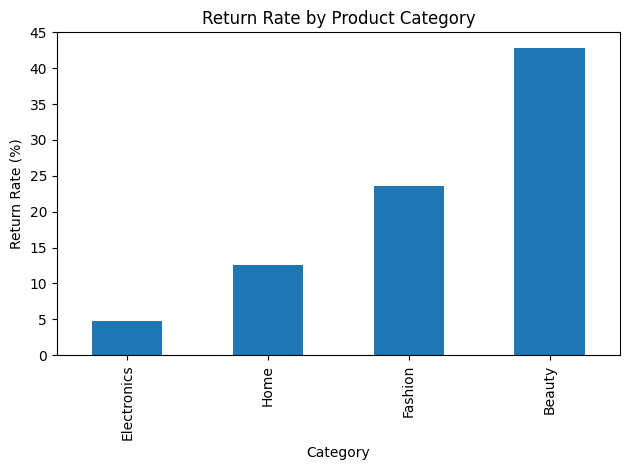


Average Discount by Return Status:
returned
0    14.050633
1    11.904762
Name: discount, dtype: float64


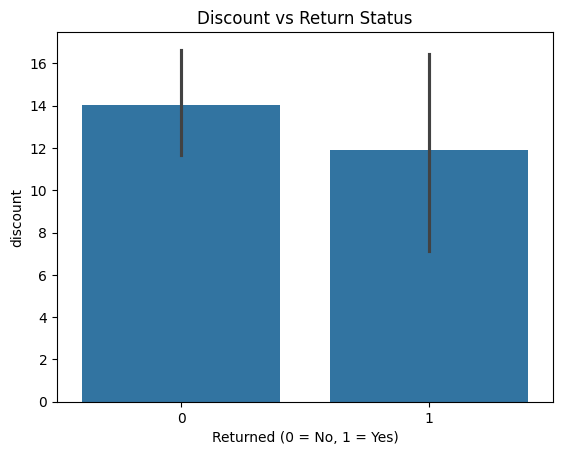


Average Delivery Delay by Return Status:
returned
0    0.531646
1    0.238095
Name: delivery_delay, dtype: float64


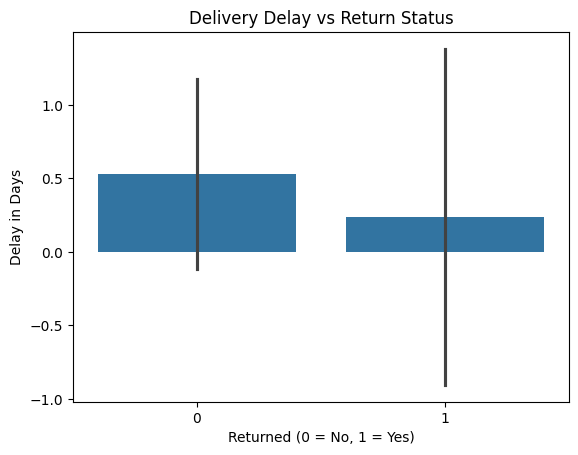


Return Reasons:
reason
Wrong Size         7
Late Delivery      4
Not as Expected    4
Damaged            4
Unknown            2
Name: count, dtype: int64


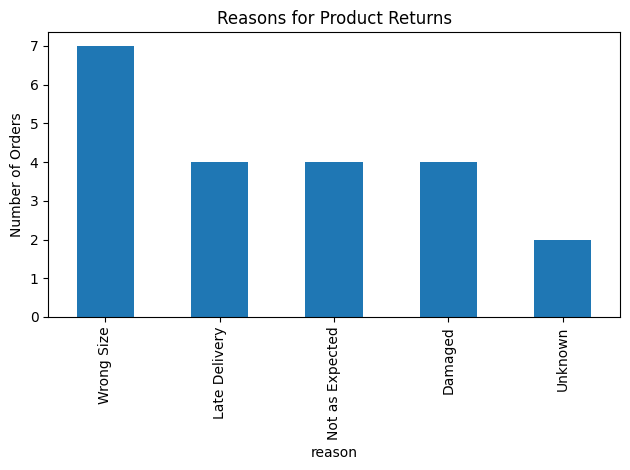

In [ ]:

# Step 5: EDA

print("Overall Return Rate:",
      round(df["returned"].mean() * 100, 2), "%")

# Return rate by category
category_returns = df.groupby("category")["returned"].mean() * 100
print("\nReturn Rate by Category:")
print(category_returns.sort_values(ascending=False))

category_returns.sort_values().plot(
    kind="bar", title="Return Rate by Product Category",
    ylabel="Return Rate (%)", xlabel="Category"
)
plt.tight_layout()
plt.show()

# Average discount for returned vs non-returned orders
print("\nAverage Discount by Return Status:")
print(df.groupby("returned")["discount"].mean())

sns.barplot(data=df, x="returned", y="discount")
plt.title("Discount vs Return Status")
plt.xlabel("Returned (0 = No, 1 = Yes)")
plt.show()

# Delivery delay analysis
print("\nAverage Delivery Delay by Return Status:")
print(df.groupby("returned")["delivery_delay"].mean())

sns.barplot(data=df, x="returned", y="delivery_delay")
plt.title("Delivery Delay vs Return Status")
plt.xlabel("Returned (0 = No, 1 = Yes)")
plt.ylabel("Delay in Days")
plt.show()

# Return reasons
reason_counts = df[df["returned"] == 1]["reason"].value_counts()
print("\nReturn Reasons:")
print(reason_counts)

reason_counts.plot(kind="bar", title="Reasons for Product Returns")
plt.ylabel("Number of Orders")
plt.tight_layout()
plt.show()


Algorithm: Logistic Regression
Accuracy: 80.0 %
F1-score: 0.0

Classification Report:
              precision    recall  f1-score   support

           0       0.80      1.00      0.89        16
           1       0.00      0.00      0.00         4

    accuracy                           0.80        20
   macro avg       0.40      0.50      0.44        20
weighted avg       0.64      0.80      0.71        20



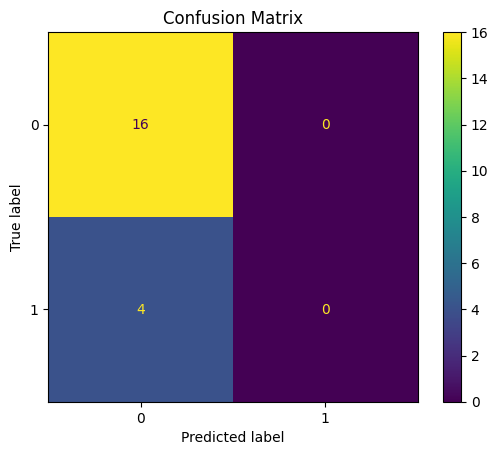

In [ ]:

# Step 6: Prepare features and train ML model

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score, classification_report
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Select input features
features = [
    "category", "price", "discount", "quantity",
    "delivery_delay", "seller", "region", "order_history"
]

X = df[features].copy()
y = df["returned"].astype(int)

# Separate categorical and numerical features
categorical_features = ["category", "seller", "region"]
numerical_features = [
    "price", "discount", "quantity",
    "delivery_delay", "order_history"
]

# Preprocess features and train the model
preprocessor = ColumnTransformer([
    ("cat", OneHotEncoder(handle_unknown="ignore"),
     categorical_features),
    ("num", StandardScaler(), numerical_features)
])

model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(max_iter=1000))
])

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

model.fit(X_train, y_train)
y_pred = model.predict(X_test)

accuracy = accuracy_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred, zero_division=0)

print("Algorithm: Logistic Regression")
print("Accuracy:", round(accuracy * 100, 2), "%")
print("F1-score:", round(f1, 3))
print("\nClassification Report:")
print(classification_report(y_test, y_pred, zero_division=0))

ConfusionMatrixDisplay.from_predictions(y_test, y_pred)
plt.title("Confusion Matrix")
plt.show()


In [ ]:

# Step 8: Export project results

# Save cleaned merged dataset
df.to_csv("cleaned_ecommerce_returns.csv", index=False)

# Prepare analysis tables
category_summary = (
    df.groupby("category")
    .agg(
        Total_Orders=("order_id", "count"),
        Returned_Orders=("returned", "sum"),
        Return_Rate=("returned", "mean")
    )
    .reset_index()
)
category_summary["Return_Rate"] *= 100

discount_summary = (
    df.groupby("returned")["discount"]
    .mean().reset_index()
)

delivery_summary = (
    df.groupby("returned")["delivery_delay"]
    .mean().reset_index()
)

model_metrics = pd.DataFrame({
    "Metric": ["Algorithm", "Accuracy (%)", "F1-score"],
    "Value": ["Logistic Regression", accuracy * 100, f1]
})

# Export multiple sheets to Excel
with pd.ExcelWriter("CH06_Return_Analysis.xlsx") as writer:
    df.to_excel(writer, sheet_name="Cleaned Data", index=False)
    category_summary.to_excel(
        writer, sheet_name="Category Analysis", index=False
    )
    reason_counts.rename("Count").to_excel(
        writer, sheet_name="Return Reasons"
    )
    discount_summary.to_excel(
        writer, sheet_name="Discount Analysis", index=False
    )
    delivery_summary.to_excel(
        writer, sheet_name="Delivery Analysis", index=False
    )
    model_metrics.to_excel(
        writer, sheet_name="Model Metrics", index=False
    )

print("Export completed successfully!")
print("1. cleaned_ecommerce_returns.csv")
print("2. CH06_Return_Analysis.xlsx")


Export completed successfully!
1. cleaned_ecommerce_returns.csv
2. CH06_Return_Analysis.xlsx
